# COMP4318/5318 Assignment 2: Image Classification

### Group number: 36  , SID1: 480076351 , SID2: 560568323 , SID3: 550205993

This notebook follows the supplied template. Sections 1-2 prepare the shared data and define/run baseline models; Section 3 records validation searches; Section 4 independently refits and tests the frozen selected models. The order is SVM, MLP, CNN throughout.

Only `Assignment2Data/X_train.npy`, `y_train.npy`, `X_test.npy` and `y_test.npy` are required beside the notebook. No model downloads, cached CSVs or external scripts are needed. Run all cells in order for full reproduction. For a shorter final-model reproduction, run **Setup, Section 1 and Section 4**; all of Section 3 and the baseline experiments may be skipped. Saved outputs include every parameter-search result.

## Setup and dependencies

Use a standard **Python 3** kernel with NumPy, pandas, Matplotlib, scikit-learn, TensorFlow/Keras, IPython and threadpoolctl. No particular environment name is required. The saved outputs were produced with Python 3.11.16 and the library versions printed below. The final-model cells were also verified with the existing Python 3.13.9 environment, TensorFlow 2.21.0 and PyArrow 22.0.0, reproducing the test scores.

**Compatibility note (macOS arm64):** on the tested machine, PyArrow 21.0.0 caused a native-library conflict with TensorFlow 2.21.0. Updating PyArrow to the tested version 22.0.0 resolved the import/training failure. PyArrow is not directly required by this notebook; this note concerns environments where it is already installed. Restart the kernel after changing installed packages.

Experiments use CPU, two numerical-computation threads and seed 42. Numerical results can vary across versions/hardware; runtimes are single-run measurements. The notebook executes no package installation or machine-specific absolute paths.

**Evaluation protocol.** Split only the supplied training data into 25,600 fitting and 6,400 validation images using stratification and seed 42. Use validation macro-F1 to select each configuration; use accuracy and then smaller parameter values to break ties. Fit PCA on fitting data only during tuning. All three final models are freshly fitted on all 32,000 supplied training images, with schedules fixed before final test scoring. The 8,000-image test set is never used to choose hyperparameters or stopping epochs.

In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from pathlib import Path
from time import perf_counter
import sys, platform, hashlib, gc
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

SEED, VALIDATION_SIZE, PCA_COMPONENTS = 42, 0.20, 64
MLP_BATCH_SIZE, CNN_BATCH_SIZE = 256, 128
MLP_MAX_EPOCHS, CNN_EPOCHS = 18, 20
CLASS_NAMES = ['adipose', 'background', 'debris', 'lymphocytes', 'mucus',
               'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma',
               'colorectal adenocarcinoma epithelium']
CLASS_IDS = np.arange(len(CLASS_NAMES))
CLASS_SHORT = ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
thread_limits = threadpool_limits(limits=2)
# A fresh kernel applies the common CPU execution policy before model creation.
try:
    tf.config.set_visible_devices([], 'GPU')
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print('Restart the kernel to apply the CPU/thread policy before a complete rerun.')
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', None)
print('Python executable:', sys.executable)
print({'Python': platform.python_version(), 'machine': platform.machine(),
       'NumPy': np.__version__, 'pandas': pd.__version__,
       'Matplotlib': matplotlib.__version__, 'scikit-learn': sklearn.__version__,
       'TensorFlow': tf.__version__, 'Keras': getattr(tf.keras, '__version__', 'bundled with TensorFlow')})
print('Execution device: CPU; numerical threads: 2; seed:', SEED)

def classification_scores(labels, predictions):
    return {'accuracy': accuracy_score(labels, predictions),
            'macro_f1': f1_score(labels, predictions, average='macro', zero_division=0),
            'balanced_accuracy': balanced_accuracy_score(labels, predictions)}

def show_final_results(name, predictions, row):
    display(pd.DataFrame([row]).round(4))
    report = pd.DataFrame(classification_report(
        y_test, predictions, labels=CLASS_IDS, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0)).T
    display(report.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score', 'support']].round(4))
    fig, ax = plt.subplots(figsize=(6.4, 5.3))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=CLASS_IDS, display_labels=CLASS_SHORT,
        cmap='Blues', values_format='d', colorbar=False, ax=ax)
    ax.set_title(name + ' test confusion matrix')
    fig.tight_layout(); plt.show()
    return report

Python executable: [local Python environment]
{'Python': '3.13.9', 'machine': 'arm64', 'NumPy': '2.3.5', 'pandas': '2.3.3', 'Matplotlib': '3.10.6', 'scikit-learn': '1.7.2', 'TensorFlow': '2.21.0', 'Keras': '3.15.1'}
Execution device: CPU; numerical threads: 2; seed: 42


## 1. Data loading, exploration, and preprocessing


### 1.1 Data loading and fitting/validation split
Use only the four Canvas-provided arrays. This is the assignment subset/split of **PathMNIST**, not the original MedMNIST split. PathMNIST contains RGB histology tissue patches from colorectal specimens, with nine tissue classes; class names follow MedMNIST metadata [1, 2].

Reserve the supplied test set for Section 4. Split the supplied training set once into 80% fitting and 20% validation data, stratified by class. All model-directed exploration below uses only the fitting partition. Reuse `fit_indices` and `val_indices` for the teammates' MLP/CNN tuning. Fit learned transformations on fitting data only; after selecting hyperparameters, refit SVM, MLP and CNN on all supplied training data. The neural networks use fixed epoch counts established from validation data. Labels remain integer encoded for compatibility with sparse multiclass neural-network losses.

The arrays do not provide patient/slide identifiers. Thus a patch-level stratified split is possible, but patient-independent validation cannot be established; this limits interpretation of generalisation.

In [2]:
DATA_DIR = Path('Assignment2Data')
required_files = ['X_train.npy', 'y_train.npy', 'X_test.npy', 'y_test.npy']
missing = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Place Assignment2Data beside the notebook. Missing: {missing}')
X_train = np.load(DATA_DIR / 'X_train.npy', allow_pickle=False)
y_train = np.load(DATA_DIR / 'y_train.npy', allow_pickle=False).reshape(-1)
X_test = np.load(DATA_DIR / 'X_test.npy', allow_pickle=False)
y_test = np.load(DATA_DIR / 'y_test.npy', allow_pickle=False).reshape(-1)

# Test checks concern file structure only; no test distribution informs design.
for images, labels in [(X_train, y_train), (X_test, y_test)]:
    assert images.ndim == 4 and images.shape[1:] == (28, 28, 3)
    assert images.dtype == np.uint8 and len(images) == len(labels)
    assert np.isin(labels, CLASS_IDS).all()
assert np.array_equal(np.unique(y_train), CLASS_IDS)
fit_indices, val_indices = train_test_split(
    np.arange(len(y_train)), test_size=VALIDATION_SIZE,
    stratify=y_train, random_state=SEED)
X_fit, y_fit = X_train[fit_indices], y_train[fit_indices]
X_val, y_val = X_train[val_indices], y_train[val_indices]
print(f'Supplied training: {X_train.shape}; labels: {y_train.shape}')
print(f'Supplied test (held out): {X_test.shape}; labels: {y_test.shape}')
print(f'Fitting: {len(y_fit):,}; validation: {len(y_val):,}; test: {len(y_test):,}')
print(f'Fitting pixel range: [{X_fit.min()}, {X_fit.max()}], dtype: {X_fit.dtype}')

Supplied training: (32000, 28, 28, 3); labels: (32000,)
Supplied test (held out): (8000, 28, 28, 3); labels: (8000,)
Fitting: 25,600; validation: 6,400; test: 8,000
Fitting pixel range: [0, 255], dtype: uint8


### 1.2 Class balance and data integrity


,class_id,class_name,provided_train_n,fit_n,validation_n,fit_percent
0,0,adipose,3490,2792,698,10.91
1,1,background,3431,2745,686,10.72
2,2,debris,3505,2804,701,10.95
3,3,lymphocytes,3656,2925,731,11.43
4,4,mucus,2950,2360,590,9.22
5,5,smooth muscle,4290,3432,858,13.41
6,6,normal colon mucosa,2728,2182,546,8.52
7,7,cancer-associated stroma,3253,2602,651,10.16
8,8,colorectal adenocarcinoma epithelium,4697,3758,939,14.68


Fitting majority/minority ratio: 1.722


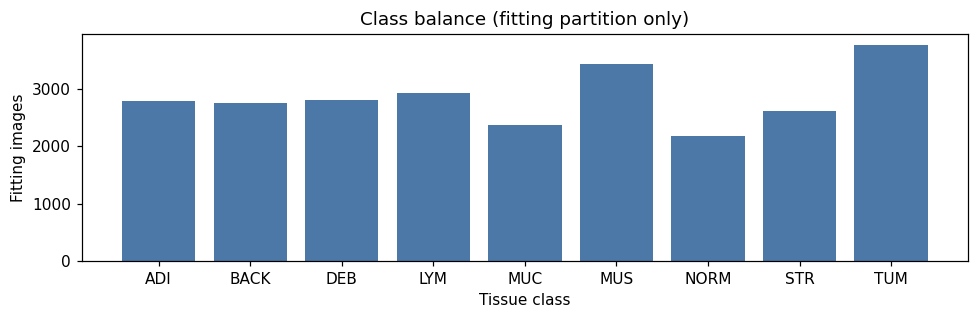

Repeated training rows: 0
Hashes shared between fitting and validation: 0
Training hashes with conflicting labels: 0


In [3]:
class_table = pd.DataFrame({
    'class_id': CLASS_IDS, 'class_name': CLASS_NAMES,
    'provided_train_n': np.bincount(y_train, minlength=9),
    'fit_n': np.bincount(y_fit, minlength=9),
    'validation_n': np.bincount(y_val, minlength=9)})
class_table['fit_percent'] = 100 * class_table['fit_n'] / len(y_fit)
display(class_table.round(2))
print('Fitting majority/minority ratio:', round(class_table.fit_n.max()/class_table.fit_n.min(), 3))
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(CLASS_SHORT, class_table.fit_n, color='#4C78A8')
ax.set(xlabel='Tissue class', ylabel='Fitting images', title='Class balance (fitting partition only)')
plt.tight_layout(); plt.show()

# Exact duplicate audit within the supplied training data, never the test set.
train_hashes = [hashlib.sha256(image.tobytes()).hexdigest() for image in X_train]
fit_hashes = {train_hashes[i] for i in fit_indices}
val_hashes = {train_hashes[i] for i in val_indices}
label_sets = {}
for image_hash, label in zip(train_hashes, y_train):
    label_sets.setdefault(image_hash, set()).add(int(label))
print('Repeated training rows:', len(train_hashes) - len(set(train_hashes)))
print('Hashes shared between fitting and validation:', len(fit_hashes & val_hashes))
print('Training hashes with conflicting labels:', sum(len(v)>1 for v in label_sets.values()))
if fit_hashes & val_hashes:
    raise ValueError('Exact duplicates cross validation boundaries: use a grouped split before tuning.')

### 1.3 Representative images and within-class variation


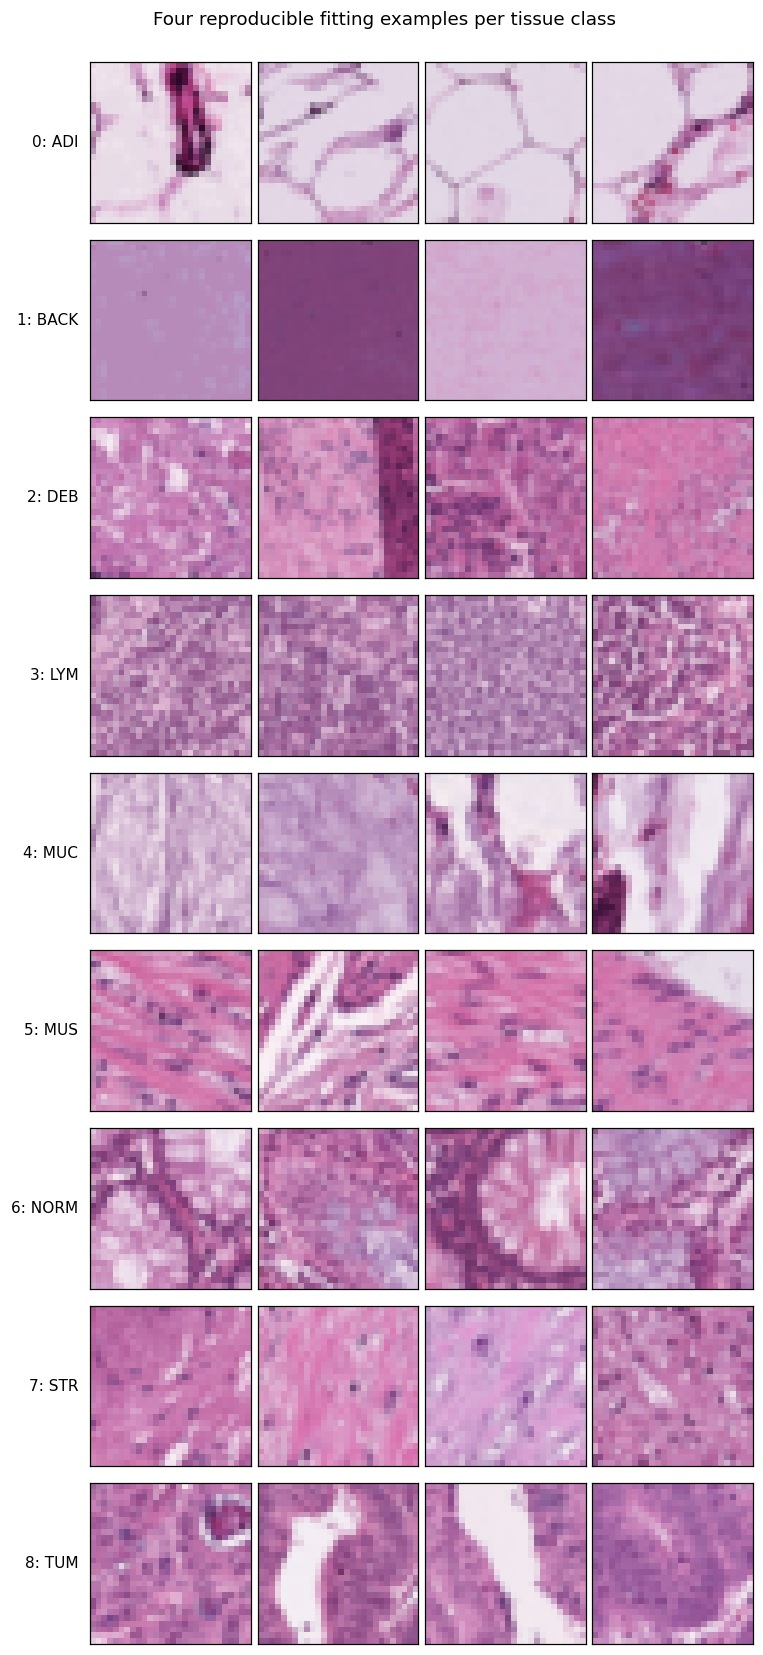

In [4]:
rng = np.random.default_rng(SEED)
example_indices = {label: rng.choice(np.flatnonzero(y_fit == label), 4, replace=False)
                   for label in CLASS_IDS}
fig, axes = plt.subplots(9, 4, figsize=(7, 15))
for label in CLASS_IDS:
    for col, index in enumerate(example_indices[label]):
        axes[label, col].imshow(X_fit[index], interpolation='nearest')
        axes[label, col].set_xticks([]); axes[label, col].set_yticks([])
    axes[label, 0].set_ylabel(f'{label}: {CLASS_SHORT[label]}', rotation=0,
                             ha='right', va='center', labelpad=8)
fig.suptitle('Four reproducible fitting examples per tissue class', y=1.0)
plt.tight_layout(); plt.show()

### 1.4 Colour, brightness and spatial characteristics


mean_R        mean_G        mean_B        mean_brightness         \
           mean    std   mean    std   mean    std            mean    std   
class_id                                                                    
0         0.844  0.031  0.761  0.047  0.848  0.031           0.818  0.036   
1         0.609  0.181  0.435  0.232  0.615  0.175           0.553  0.195   
2         0.752  0.062  0.485  0.086  0.698  0.068           0.645  0.060   
3         0.693  0.041  0.494  0.055  0.664  0.039           0.617  0.044   
4         0.767  0.041  0.601  0.072  0.752  0.047           0.707  0.052   
5         0.783  0.045  0.521  0.091  0.722  0.052           0.675  0.058   
6         0.732  0.050  0.524  0.077  0.693  0.056           0.650  0.060   
7         0.772  0.040  0.524  0.061  0.715  0.042           0.671  0.046   
8         0.710  0.051  0.480  0.070  0.663  0.052           0.618  0.057   

         within_image_std         
                     mean    std  
class_id                          
0                   0.092  0.029  
1                   0.094  0.032  
2                   0.146  0.033  
3                   0.134  0.019  
4                   0.123  0.025  
5                   0.145  0.022  
6                   0.151  0.020  
7                   0.128  0.014  
8                   0.151  0.025

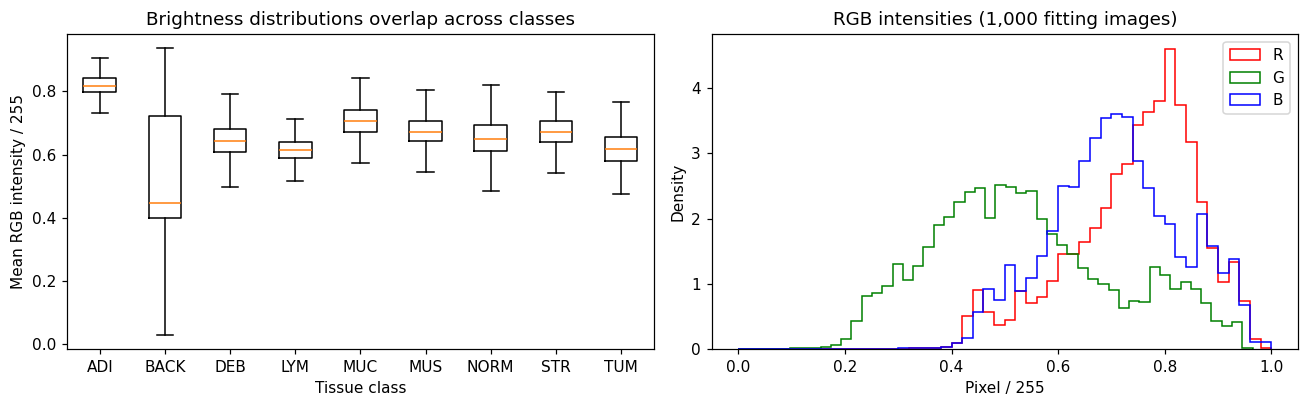

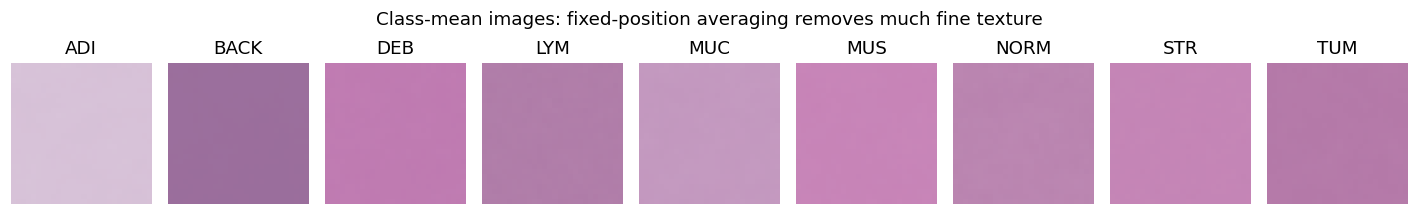

In [5]:
image_rgb_means = X_fit.mean(axis=(1, 2)) / 255.0
image_brightness = image_rgb_means.mean(axis=1)
image_contrast = X_fit.astype(np.float32).std(axis=(1, 2, 3)) / 255.0
colour_table = pd.DataFrame({
    'class_id': y_fit, 'mean_R': image_rgb_means[:, 0],
    'mean_G': image_rgb_means[:, 1], 'mean_B': image_rgb_means[:, 2],
    'mean_brightness': image_brightness, 'within_image_std': image_contrast
}).groupby('class_id').agg(['mean', 'std'])
display(colour_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].boxplot([image_brightness[y_fit == label] for label in CLASS_IDS],
                showfliers=False)
axes[0].set_xticks(np.arange(1, 10), CLASS_SHORT)
axes[0].set(title='Brightness distributions overlap across classes',
            xlabel='Tissue class', ylabel='Mean RGB intensity / 255')
pixel_sample = X_fit[rng.choice(len(X_fit), 1000, replace=False)].reshape(-1, 3)/255.0
for channel, name in enumerate(['R', 'G', 'B']):
    axes[1].hist(pixel_sample[:, channel], bins=50, histtype='step', density=True,
                 label=name, color=['red', 'green', 'blue'][channel])
axes[1].set(title='RGB intensities (1,000 fitting images)', xlabel='Pixel / 255', ylabel='Density')
axes[1].legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 9, figsize=(13, 2))
for label, ax in zip(CLASS_IDS, axes):
    ax.imshow(X_fit[y_fit == label].mean(axis=0)/255.0)
    ax.set_title(CLASS_SHORT[label]); ax.axis('off')
fig.suptitle('Class-mean images: fixed-position averaging removes much fine texture')
plt.tight_layout(); plt.show()

### 1.5 Preprocessing decisions and model inputs
- All images have the same small RGB shape and bounded integer intensities, so no resizing, missing-value imputation or clipping of the original data is necessary. Preserve all colour channels because staining/colour differences may help separate tissue classes.
- Sample patches and class-mean images allow inspection of texture and spatial variation. Histology patches are not aligned single objects; averaging at fixed coordinates blurs fine structures. A flattened-pixel SVM therefore lacks the local, shared filters that a CNN can learn.
- Brightness/colour distributions overlap, and the sample grid shows within-class variation. Colour alone cannot be assumed sufficient; potential confusions must be checked against the final confusion matrix rather than asserted as results beforehand.
- Class frequencies differ moderately. For all three models, use **macro-F1** as the predeclared tuning criterion, giving equal weight to each tissue class; also report accuracy and balanced accuracy. No resampling is applied.
- Divide pixels by 255 and cast to `float32`. Keep 4D arrays for neural networks, and flatten copies to 2,352 features for SVM. This fixed scaling learns nothing from validation/test data.
- For SVM, fit 64-component PCA **only on fitting data**, then whiten retained components to approximately unit variance. This reduces kernel-distance cost and avoids the largest-variance components dominating distances [3]. PCA may discard class-relevant detail, and whitening may amplify low-variance noise; 64 is a fixed runtime compromise, not a claim of optimal dimensionality or 95% retained variance.
- Do not crop, remove pale/background patches, convert to grayscale, perform stain normalisation, or augment images in this study. These choices could discard labelled background/colour information or require further validation. No patient/slide grouping information is available.

**Observed examples:** adipose patches contain large pale regions separated by stained boundaries; background examples are comparatively uniform but vary in brightness; lymphocyte examples contain dense dark speckles. Smooth-muscle and stroma examples both contain pink, sometimes elongated structures, suggesting a potential visual difficulty. These are qualitative observations from the fitting examples, not a clinical interpretation.

In [6]:
def scale_images(images):
    """Fixed [0, 255] -> float32 [0, 1] scaling, with NHWC layout retained."""
    return np.asarray(images, dtype=np.float32) / np.float32(255.0)

def flatten_and_scale(images):
    scaled = scale_images(images)
    return scaled.reshape(len(scaled), -1)

X_fit_scaled, X_val_scaled = scale_images(X_fit), scale_images(X_val)
started = perf_counter()
svm_pca = PCA(n_components=PCA_COMPONENTS, whiten=True,
              svd_solver='randomized', random_state=SEED)
X_fit_svm = svm_pca.fit_transform(flatten_and_scale(X_fit))
X_val_svm = svm_pca.transform(flatten_and_scale(X_val))
pca_fit_transform_seconds = perf_counter() - started
print('Neural-network fitting/validation shapes:', X_fit_scaled.shape, X_val_scaled.shape)
print('SVM fitting/validation shapes:', X_fit_svm.shape, X_val_svm.shape)
print(f'PCA retained variance: {svm_pca.explained_variance_ratio_.sum():.2%}')
print(f'Shared PCA fit and fitting/validation transforms: {pca_fit_transform_seconds:.2f}s')

Neural-network fitting/validation shapes: (25600, 28, 28, 3) (6400, 28, 28, 3)
SVM fitting/validation shapes: (25600, 64) (6400, 64)
PCA retained variance: 81.57%
Shared PCA fit and fitting/validation transforms: 1.47s


### 1.6 Examples after preprocessing


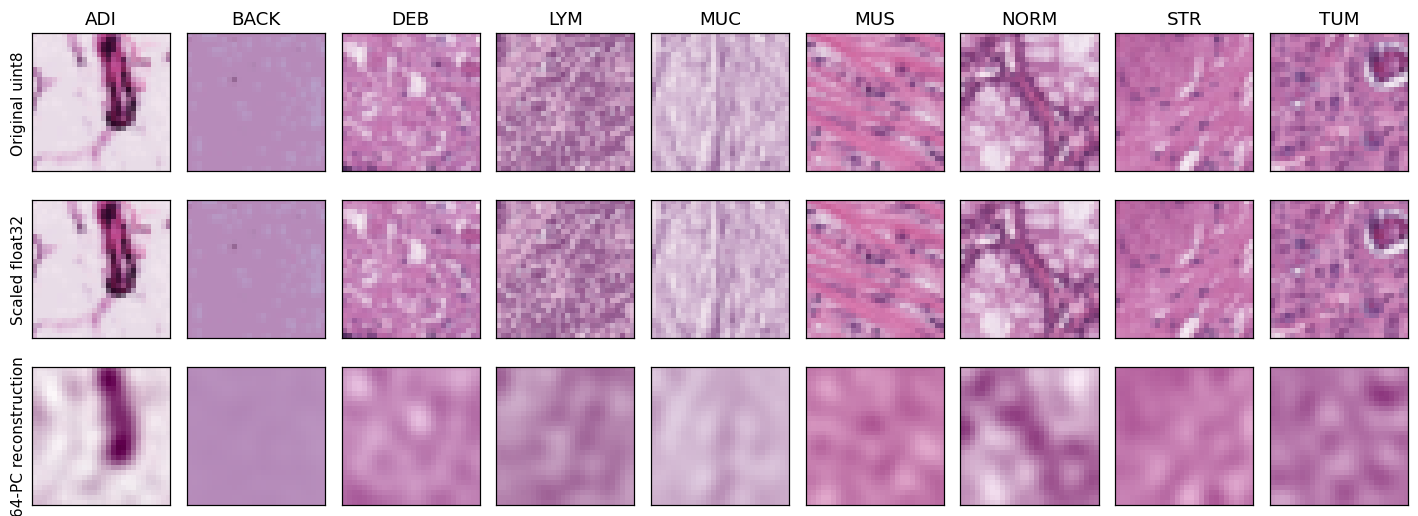

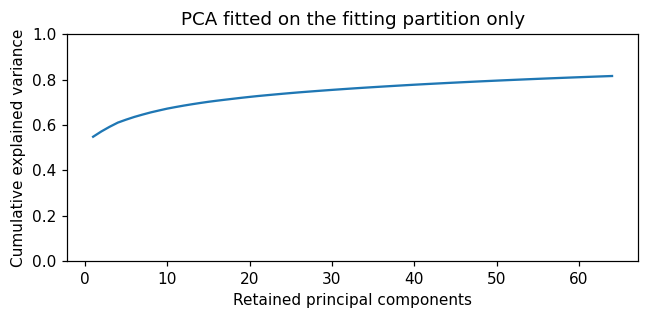

First image: first 10 scaled pixel features: [0.69803923 0.34901962 0.5764706  0.72156864 0.3647059  0.59607846
 0.7490196  0.39215687 0.6431373  0.6901961 ]
First image: first 10 whitened PCA features: [-0.38037804  1.0667882  -0.00815488  0.6274867  -0.04508182  0.5252834
  0.20348658 -0.08347911  0.4108618  -0.12514837]


In [7]:
chosen = np.array([example_indices[label][0] for label in CLASS_IDS])
reconstructed = svm_pca.inverse_transform(X_fit_svm[chosen]).reshape(-1, 28, 28, 3)
fig, axes = plt.subplots(3, 9, figsize=(13, 5))
for col, index in enumerate(chosen):
    axes[0, col].imshow(X_fit[index]); axes[0, col].set_title(CLASS_SHORT[col])
    axes[1, col].imshow(X_fit_scaled[index])
    # Clip only the PCA reconstruction for display; model features are not clipped.
    axes[2, col].imshow(np.clip(reconstructed[col], 0, 1))
    for row in range(3):
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
for row, name in enumerate(['Original uint8', 'Scaled float32', '64-PC reconstruction']):
    axes[row, 0].set_ylabel(name)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, PCA_COMPONENTS+1), np.cumsum(svm_pca.explained_variance_ratio_))
ax.set(xlabel='Retained principal components', ylabel='Cumulative explained variance',
       title='PCA fitted on the fitting partition only', ylim=(0, 1))
plt.tight_layout(); plt.show()
print('First image: first 10 scaled pixel features:', flatten_and_scale(X_fit[:1])[0, :10])
print('First image: first 10 whitened PCA features:', X_fit_svm[0, :10])

## 2. Algorithm design and setup

Define the three models and run the baseline experiments in order: **SVM, MLP, CNN**. These are initial models; final models are trained in Section 4.


### 2.1 SVM — design and baseline model


**Choice: RBF-kernel support vector machine, with PCA.** SVM learns margin-based decision boundaries; larger `C` penalises training errors more strongly. The RBF kernel is $K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$: small `gamma` gives broad influence/smoother boundaries, while large `gamma` allows more local boundaries and can overfit. `SVC` trains one-vs-one classifiers internally (36 for nine classes) [3].

This is a nonlinear non-neural comparator with a different inductive bias from the MLP/CNN. It handles moderate feature spaces without designing a neural architecture, but has potentially expensive kernel training and prediction, limited interpretability, no built-in translation invariance, and a dependence on preprocessing and hyperparameters. The baseline uses `C=1`, `gamma=0.01`, unweighted classes and `probability=False`; probability calibration is unnecessary for the chosen metrics. The fixed 64-PC representation is shared across baseline and tuning.

The helper below returns validation predictions/metrics and separate fit/prediction times. It never accepts test data. A reproducible sample of up to 3,000 fitting rows provides a descriptive training macro-F1 for diagnosing overfitting; this sampled training score is explicitly labelled and never used to select parameters.

In [8]:
train_diagnostic_indices = np.random.default_rng(SEED).choice(
    len(y_fit), min(3000, len(y_fit)), replace=False)

def evaluate_svm(C, gamma):
    model = SVC(C=C, gamma=gamma, kernel='rbf', cache_size=512,
                class_weight=None)
    started = perf_counter()
    model.fit(X_fit_svm, y_fit)
    fit_seconds = perf_counter() - started
    started = perf_counter()
    predictions = model.predict(X_val_svm)
    predict_seconds = perf_counter() - started
    started = perf_counter()
    train_predictions = model.predict(X_fit_svm[train_diagnostic_indices])
    diagnostic_seconds = perf_counter() - started
    record = {
        'C': C, 'gamma': gamma,
        'validation_macro_f1': f1_score(y_val, predictions, average='macro', zero_division=0),
        'validation_accuracy': accuracy_score(y_val, predictions),
        'validation_balanced_accuracy': balanced_accuracy_score(y_val, predictions),
        'train_sample_macro_f1': f1_score(y_fit[train_diagnostic_indices], train_predictions,
                                         average='macro', zero_division=0),
        'fit_seconds': fit_seconds, 'validation_predict_seconds': predict_seconds,
        'train_diagnostic_seconds': diagnostic_seconds,
        'support_vectors': int(model.n_support_.sum())}
    record['candidate_total_seconds'] = fit_seconds + predict_seconds + diagnostic_seconds
    return model, record

baseline_svm, baseline_record = evaluate_svm(C=1.0, gamma=0.01)
display(pd.DataFrame([baseline_record]).round(4))
print('Majority-class validation accuracy reference:',
      accuracy_score(y_val, np.full(len(y_val), np.bincount(y_fit).argmax())))
del baseline_svm
_ = gc.collect()

,C,gamma,validation_macro_f1,validation_accuracy,validation_balanced_accuracy,train_sample_macro_f1,fit_seconds,validation_predict_seconds,train_diagnostic_seconds,support_vectors,candidate_total_seconds
0,1.0,0.01,0.618,0.6381,0.6221,0.7695,17.081,15.6568,7.3212,22204,40.059


Majority-class validation accuracy reference: 0.14671875


### 2.2 MLP — design and baseline model


**Feedforward MLP design.** Each 28 × 28 × 3 image is scaled to `[0, 1]` by the existing `scale_images` function and flattened inside the network to 2,352 inputs. Two fully connected ReLU layers learn nonlinear combinations of pixel values. A dropout layer regularises the second hidden representation; a nine-unit softmax returns class probabilities. Sparse categorical cross-entropy matches the existing integer labels. Adam is used for optimisation. The baseline has 128 and 64 hidden units, dropout 0.2, and learning rate 0.001. This modest size keeps the 2,352-to-first-layer weight matrix and CPU search cost manageable. Flattening provides no explicit local spatial bias and can overfit, motivating the held-out validation search.

The same fitting and validation indices, scaled images, class order, and macro-F1 definition as the SVM are used. The test set is untouched here. TensorFlow's random seed is reset before each new fit; CPU timings and floating-point results can still vary by machine and library version.

In [9]:
def build_mlp(hidden_units=128, dropout_rate=0.2, learning_rate=0.001):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 3)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_units, activation='relu'),
        tf.keras.layers.Dense(hidden_units // 2, activation='relu'),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(len(CLASS_IDS), activation='softmax')], name='pathmnist_mlp')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def fit_and_score_mlp(params, max_epochs=MLP_MAX_EPOCHS, patience=3):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_mlp(**params)
    stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', mode='min', patience=patience, restore_best_weights=True)
    started = perf_counter()
    history = model.fit(X_fit_scaled, y_fit, validation_data=(X_val_scaled, y_val),
                        epochs=max_epochs, batch_size=MLP_BATCH_SIZE, shuffle=True,
                        callbacks=[stopping], verbose=0)
    fit_seconds = perf_counter() - started
    started = perf_counter()
    predictions = model.predict(X_val_scaled, batch_size=MLP_BATCH_SIZE,
                                 verbose=0).argmax(axis=1)
    predict_seconds = perf_counter() - started
    best_epoch = int(np.argmin(history.history['val_loss'])) + 1
    metrics = classification_scores(y_val, predictions)
    record = {**params, **{'validation_' + key: value for key, value in metrics.items()},
              'fit_seconds': fit_seconds, 'validation_predict_seconds': predict_seconds,
              'epochs_run': len(history.history['loss']), 'best_val_loss_epoch': best_epoch,
              'parameters': model.count_params(),
              'train_accuracy_at_best_epoch': history.history['accuracy'][best_epoch - 1],
              'validation_accuracy_at_best_epoch': history.history['val_accuracy'][best_epoch - 1]}
    curves = {key: list(values) for key, values in history.history.items()}
    del model
    tf.keras.backend.clear_session(); _ = gc.collect()
    return record, curves

In [10]:
BASELINE_MLP_PARAMS = {'hidden_units': 128, 'dropout_rate': 0.2,
                       'learning_rate': 0.001}
baseline_mlp_record, baseline_mlp_curves = fit_and_score_mlp(
    BASELINE_MLP_PARAMS, max_epochs=12, patience=3)
display(pd.DataFrame([baseline_mlp_record]).round(4))
print('Baseline uses the fitting/validation split only; the test set was not evaluated.')

,hidden_units,dropout_rate,learning_rate,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,fit_seconds,validation_predict_seconds,epochs_run,best_val_loss_epoch,parameters,train_accuracy_at_best_epoch,validation_accuracy_at_best_epoch
0,128,0.2,0.001,0.4934,0.4507,0.4793,6.1988,0.1048,12,10,310025,0.4529,0.4934


Baseline uses the fitting/validation split only; the test set was not evaluated.


### 2.3 CNN — design and baseline model


**CNN design.** Two valid 3x3 ReLU convolution layers, with F and 2F filters, each followed by 2x2 max pooling, then Flatten, Dropout and a nine-class softmax. This is a small manually implemented classroom architecture rather than a pretrained model. Spatial sizes are 28 -> 26 -> 13 -> 11 -> 5. Pixels are scaled before fitting; labels stay integer encoded. The baseline uses F=32, dropout 0.5, Adam learning rate 0.001, batch size 128 and ten epochs. Tuning uses a fixed twenty-epoch budget for every candidate.

In [11]:
def build_cnn(base_filters=32, dropout_rate=0.5, learning_rate=0.001):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 3)),
        tf.keras.layers.Conv2D(base_filters, (3, 3), activation='relu', padding='valid'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(base_filters * 2, (3, 3), activation='relu', padding='valid'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(len(CLASS_IDS), activation='softmax')], name='pathmnist_cnn')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def fit_and_score_cnn(params, epochs=CNN_EPOCHS):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn(**params)
    started = perf_counter()
    history = model.fit(X_fit_scaled, y_fit, validation_data=(X_val_scaled, y_val),
                        epochs=epochs, batch_size=CNN_BATCH_SIZE, shuffle=True, verbose=0)
    fit_seconds = perf_counter() - started
    started = perf_counter()
    predictions = model.predict(X_val_scaled, batch_size=CNN_BATCH_SIZE,
                                 verbose=0).argmax(axis=1)
    predict_seconds = perf_counter() - started
    metrics = classification_scores(y_val, predictions)
    record = {**params, **{'validation_' + key: value for key, value in metrics.items()},
              'fit_seconds': fit_seconds, 'validation_predict_seconds': predict_seconds,
              'epochs_run': len(history.history['loss']),
              'validation_loss': float(history.history['val_loss'][-1]),
              'parameters': model.count_params()}
    curves = {key: list(values) for key, values in history.history.items()}
    del model
    tf.keras.backend.clear_session(); _ = gc.collect()
    return record, curves

BASELINE_CNN_PARAMS = {'base_filters': 32, 'dropout_rate': 0.5, 'learning_rate': 0.001}
baseline_cnn_record, baseline_cnn_curves = fit_and_score_cnn(BASELINE_CNN_PARAMS, epochs=10)
display(pd.DataFrame([baseline_cnn_record]).round(4))

,base_filters,dropout_rate,learning_rate,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,fit_seconds,validation_predict_seconds,epochs_run,validation_loss,parameters
0,32,0.5,0.001,0.712,0.7031,0.7015,72.3849,0.5804,10,0.8177,33801


## 3. Hyperparameter tuning

Tune each model using fitting/validation data, in order: **SVM, MLP, CNN**. Record validation results and runtime. Final test evaluation follows in Section 4.


### 3.1 SVM — hyperparameter search and validation results


**Search strategy:** exhaustive grid search on the same fixed stratified holdout. Search `C = [1, 10, 100]` and `gamma = [0.001, 0.01, 0.1]` (nine combinations). Values span orders of magnitude and test smooth through local decision boundaries. The baseline (`C=1`, `gamma=0.01`) is in the grid. PCA dimensionality/whitening are held fixed to make this search affordable and comparisons controlled.

Fit PCA once on fitting data and reuse its transformed arrays for every candidate; this is valid because the validation set is never used to fit PCA. Each candidate is a fresh SVC. Select the highest validation macro-F1; break exact ties by accuracy, then smaller `C`, then smaller `gamma`. The recorded SVC times exclude the one-off shared PCA cost, printed separately. Total search wall time includes all candidate fitting, predictions, diagnostics and overhead. Only the selected configuration will be evaluated on the test set in Section 4.

A single holdout makes this feasible on a CPU and shares a protocol with neural-network early stopping/tuning. Its limitations are split variability and optimism from repeatedly selecting on the same validation set; no cross-validation uncertainty is claimed. The grid is bounded rather than globally optimal. All fitting rows are used (no training subsampling).

In [12]:
search_grid = {'C': [1.0, 10.0, 100.0], 'gamma': [0.001, 0.01, 0.1]}
search_records = []
search_start = perf_counter()
for number, params in enumerate(ParameterGrid(search_grid), start=1):
    _, record = evaluate_svm(**params)
    search_records.append(record)
    print(f"{number}/9: C={params['C']:g}, gamma={params['gamma']:g}, "
          f"validation macro-F1={record['validation_macro_f1']:.4f}, "
          f"accuracy={record['validation_accuracy']:.4f}, "
          f"fit={record['fit_seconds']:.2f}s", flush=True)
search_wall_seconds = perf_counter() - search_start
svm_search_results = pd.DataFrame(search_records).sort_values(
    ['validation_macro_f1', 'validation_accuracy', 'C', 'gamma'],
    ascending=[False, False, True, True]).reset_index(drop=True)
selected_row = svm_search_results.iloc[0]
selected_svm_params = {'C': float(selected_row['C']), 'gamma': float(selected_row['gamma'])}
display(svm_search_results.round(4))
print('Selected by validation macro-F1, with predefined tie-breaks:', selected_svm_params)
print(f'Search wall time: {search_wall_seconds:.2f}s; shared preprocessing: {pca_fit_transform_seconds:.2f}s')
print('Selection does not use any test-set scores.')

1/9: C=1, gamma=0.001, validation macro-F1=0.5164, accuracy=0.5748, fit=19.28s
2/9: C=1, gamma=0.01, validation macro-F1=0.6180, accuracy=0.6381, fit=17.26s
3/9: C=1, gamma=0.1, validation macro-F1=0.4279, accuracy=0.4448, fit=37.29s
4/9: C=10, gamma=0.001, validation macro-F1=0.6016, accuracy=0.6278, fit=13.87s
5/9: C=10, gamma=0.01, validation macro-F1=0.6226, accuracy=0.6294, fit=18.02s
6/9: C=10, gamma=0.1, validation macro-F1=0.4372, accuracy=0.4530, fit=37.69s
7/9: C=100, gamma=0.001, validation macro-F1=0.6179, accuracy=0.6336, fit=18.11s
8/9: C=100, gamma=0.01, validation macro-F1=0.5944, accuracy=0.5994, fit=22.70s
9/9: C=100, gamma=0.1, validation macro-F1=0.4370, accuracy=0.4528, fit=39.71s


,C,gamma,validation_macro_f1,validation_accuracy,validation_balanced_accuracy,train_sample_macro_f1,fit_seconds,validation_predict_seconds,train_diagnostic_seconds,support_vectors,candidate_total_seconds
0,10.0,0.010,0.6226,0.6294,0.6240,0.9174,18.0183,14.9028,7.1254,20936,40.0465
1,1.0,0.010,0.6180,0.6381,0.6221,0.7695,17.2593,16.2506,7.5931,22204,41.1031
2,100.0,0.001,0.6179,0.6336,0.6242,0.7751,18.1090,14.3837,6.7282,19957,39.2209
3,10.0,0.001,0.6016,0.6278,0.6104,0.6514,13.8742,15.4294,7.0350,21329,36.3387
4,100.0,0.010,0.5944,0.5994,0.5958,0.9812,22.7018,14.8680,6.9614,20492,44.5312
5,1.0,0.001,0.5164,0.5748,0.5493,0.5314,19.2848,16.9534,8.0001,23214,44.2383
6,10.0,0.100,0.4372,0.4530,0.4211,1.0000,37.6937,16.7212,7.8547,23110,62.2696
7,100.0,0.100,0.4370,0.4528,0.4210,1.0000,39.7076,16.6616,7.8139,23105,64.1830
8,1.0,0.100,0.4279,0.4448,0.4125,0.9840,37.2935,16.8727,7.7266,23094,61.8928


Selected by validation macro-F1, with predefined tie-breaks: {'C': 10.0, 'gamma': 0.01}
Search wall time: 433.86s; shared preprocessing: 1.47s
Selection does not use any test-set scores.


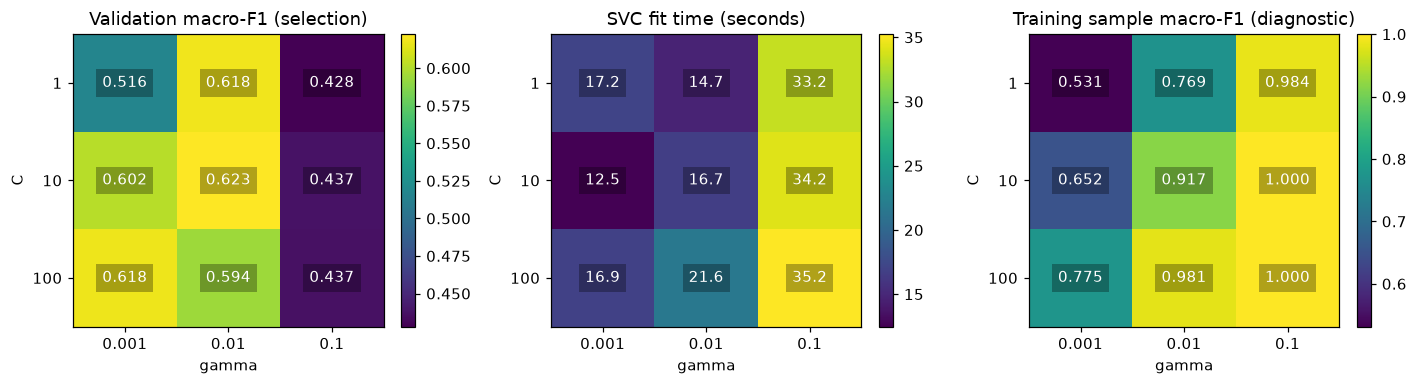

The best tested configuration was **C=10, gamma=0.01**, with validation macro-F1 **0.6226** and accuracy **0.6294**. Its sampled training macro-F1 was 0.9174. Compare the training/validation heatmaps for evidence of overfitting. These are holdout estimates, not test results; the best tested values need not be global optima.

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric, title in zip(axes,
        ['validation_macro_f1', 'fit_seconds', 'train_sample_macro_f1'],
        ['Validation macro-F1 (selection)', 'SVC fit time (seconds)', 'Training sample macro-F1 (diagnostic)']):
    table = svm_search_results.pivot(index='C', columns='gamma', values=metric).sort_index()
    im = ax.imshow(table.to_numpy(), cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(table.columns)), [f'{v:g}' for v in table.columns])
    ax.set_yticks(range(len(table.index)), [f'{v:g}' for v in table.index])
    ax.set(xlabel='gamma', ylabel='C', title=title)
    for i in range(len(table.index)):
        for j in range(len(table.columns)):
            ax.text(j, i, f'{table.iloc[i,j]:.3f}' if metric!='fit_seconds' else f'{table.iloc[i,j]:.1f}',
                    ha='center', va='center', color='white',
                    bbox={'facecolor':'black', 'alpha':.3, 'edgecolor':'none'})
    fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()
display(Markdown(
    f"The best tested configuration was **C={selected_svm_params['C']:g}, "
    f"gamma={selected_svm_params['gamma']:g}**, with validation macro-F1 "
    f"**{selected_row['validation_macro_f1']:.4f}** and accuracy "
    f"**{selected_row['validation_accuracy']:.4f}**. "
    f"Its sampled training macro-F1 was {selected_row['train_sample_macro_f1']:.4f}. "
    "Compare the training/validation heatmaps for evidence of overfitting. "
    "These are holdout estimates, not test results; the best tested values need not be global optima."))

The heatmaps compare all nine settings. Training macro-F1 is measured on the same reproducible 3,000-row diagnostic subset for every candidate. A high sampled-training score with a low validation score is evidence of overfitting. PCA dimension and whitening were fixed before this grid; they were not selected on the test set.

### 3.2 MLP — hyperparameter search and validation results


**Bounded grid search.** Evaluate all eight combinations of first-layer width `{128, 256}`, dropout `{0.2, 0.4}`, and Adam learning rate `{0.001, 0.0003}`. The second layer has half the selected first-layer width. Width tests model capacity and computational cost; dropout tests regularisation; the learning rates test faster versus more cautious optimisation. All candidates use the same 25,600 fitting and 6,400 validation images, batch size 256, and at most 18 epochs. A fresh model and the same random seed are used for every combination. Early stopping monitors **validation loss** with patience 3 and restores the lowest-loss weights. Candidate ranking uses **validation macro-F1**, with accuracy, smaller width, smaller dropout, and smaller learning rate as fixed tie breakers. The best validation-loss epoch supplies a preselected full-training epoch count; the test set is never used in this search.

Training time covers `fit` including validation and callbacks. Prediction time covers only validation inference. A single holdout and one seed limit uncertainty estimates; the grid is deliberately bounded for CPU feasibility. This cell is optional during a marker rerun because Section 4 contains literal selected values and creates a new model.

In [14]:
MLP_SEARCH_GRID = {
    'hidden_units': [128, 256],
    'dropout_rate': [0.2, 0.4],
    'learning_rate': [0.001, 0.0003],
}
mlp_search_records = []
mlp_search_histories = {}
mlp_search_started = perf_counter()
for candidate_no, params in enumerate(ParameterGrid(MLP_SEARCH_GRID), start=1):
    record, curves = fit_and_score_mlp(params, max_epochs=18, patience=3)
    record['candidate'] = candidate_no
    mlp_search_records.append(record)
    mlp_search_histories[candidate_no] = curves
    print(f"{candidate_no}/8: width={params['hidden_units']}, "
          f"dropout={params['dropout_rate']}, lr={params['learning_rate']}, "
          f"macro-F1={record['validation_macro_f1']:.4f}, "
          f"accuracy={record['validation_accuracy']:.4f}, "
          f"fit={record['fit_seconds']:.1f}s, epochs={record['epochs_run']}",
          flush=True)
mlp_search_wall_seconds = perf_counter() - mlp_search_started
mlp_search_results = pd.DataFrame(mlp_search_records).sort_values(
    ['validation_macro_f1', 'validation_accuracy', 'hidden_units',
     'dropout_rate', 'learning_rate'],
    ascending=[False, False, True, True, True]).reset_index(drop=True)
mlp_selected = mlp_search_results.iloc[0]
selected_mlp_params = {
    'hidden_units': int(mlp_selected['hidden_units']),
    'dropout_rate': float(mlp_selected['dropout_rate']),
    'learning_rate': float(mlp_selected['learning_rate']),
}
selected_mlp_epochs = int(mlp_selected['best_val_loss_epoch'])
display(mlp_search_results.round(4))
print('Selected parameters:', selected_mlp_params,
      '; full-training epochs:', selected_mlp_epochs)
print(f'Total MLP search wall time: {mlp_search_wall_seconds:.1f} s')

1/8: width=128, dropout=0.2, lr=0.001, macro-F1=0.4649, accuracy=0.5061, fit=9.5s, epochs=18
2/8: width=128, dropout=0.2, lr=0.0003, macro-F1=0.4472, accuracy=0.4941, fit=9.4s, epochs=18
3/8: width=256, dropout=0.2, lr=0.001, macro-F1=0.4609, accuracy=0.5067, fit=15.6s, epochs=18
4/8: width=256, dropout=0.2, lr=0.0003, macro-F1=0.4614, accuracy=0.5070, fit=15.9s, epochs=18
5/8: width=128, dropout=0.4, lr=0.001, macro-F1=0.4541, accuracy=0.4997, fit=8.2s, epochs=16
6/8: width=128, dropout=0.4, lr=0.0003, macro-F1=0.4197, accuracy=0.4802, fit=9.7s, epochs=18
7/8: width=256, dropout=0.4, lr=0.001, macro-F1=0.4624, accuracy=0.5009, fit=17.9s, epochs=18
8/8: width=256, dropout=0.4, lr=0.0003, macro-F1=0.4540, accuracy=0.5025, fit=15.7s, epochs=18
Selected parameters: {'hidden_units': 128, 'dropout_rate': 0.2, 'learning_rate': 0.001} ; full-training epochs: 18
Total MLP search wall time: 106.1 s


,dropout_rate,hidden_units,learning_rate,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,fit_seconds,validation_predict_seconds,epochs_run,best_val_loss_epoch,parameters,train_accuracy_at_best_epoch,validation_accuracy_at_best_epoch,candidate
0,0.2,128,0.0010,0.5061,0.4649,0.4915,9.4664,0.1124,18,18,310025,0.4816,0.5061,1
1,0.4,256,0.0010,0.5009,0.4624,0.4838,17.8787,0.1721,18,17,636425,0.4636,0.5009,7
2,0.2,256,0.0003,0.5070,0.4614,0.4915,15.8814,0.1567,18,18,636425,0.4764,0.5070,4
3,0.2,256,0.0010,0.5067,0.4609,0.4927,15.6021,0.1415,18,18,636425,0.4761,0.5067,3
4,0.4,128,0.0010,0.4997,0.4541,0.4801,8.1740,0.1116,16,13,310025,0.4480,0.4997,5
5,0.4,256,0.0003,0.5025,0.4540,0.4848,15.7033,0.1525,18,18,636425,0.4646,0.5025,8
6,0.2,128,0.0003,0.4941,0.4472,0.4770,9.3591,0.1155,18,17,310025,0.4609,0.4941,2
7,0.4,128,0.0003,0.4802,0.4197,0.4616,9.6591,0.1216,18,17,310025,0.4330,0.4802,6


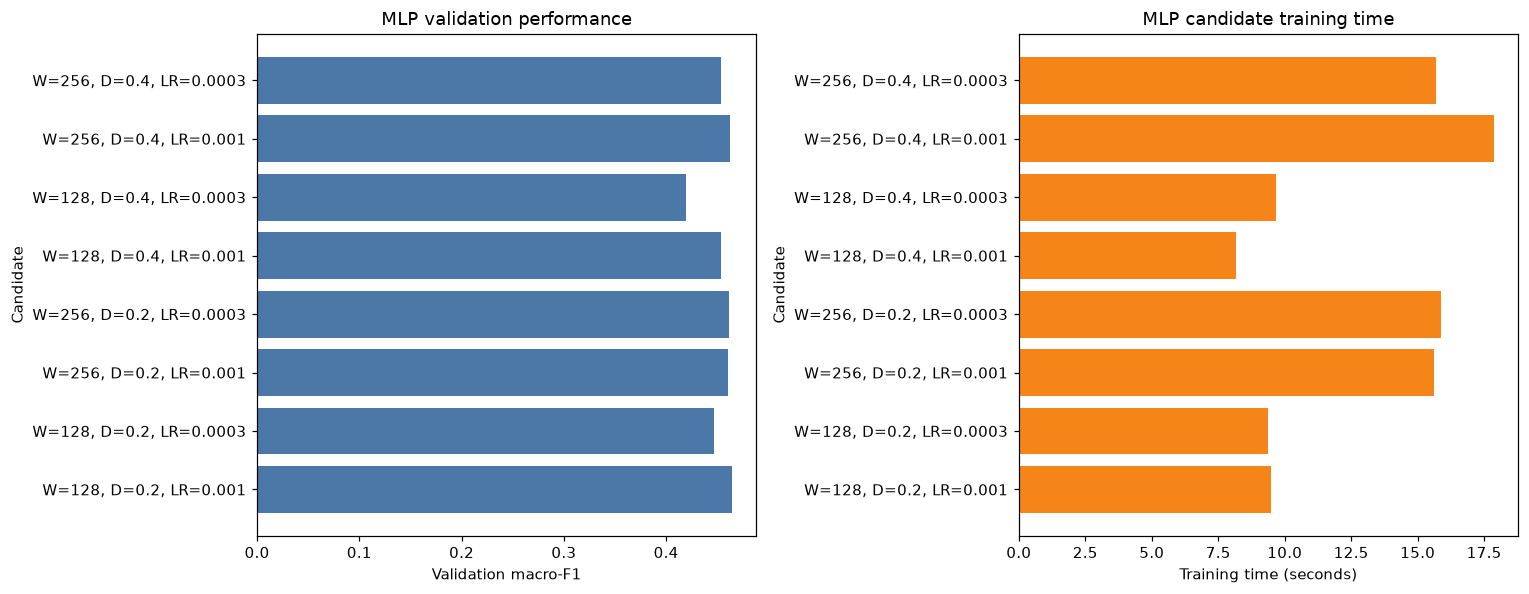

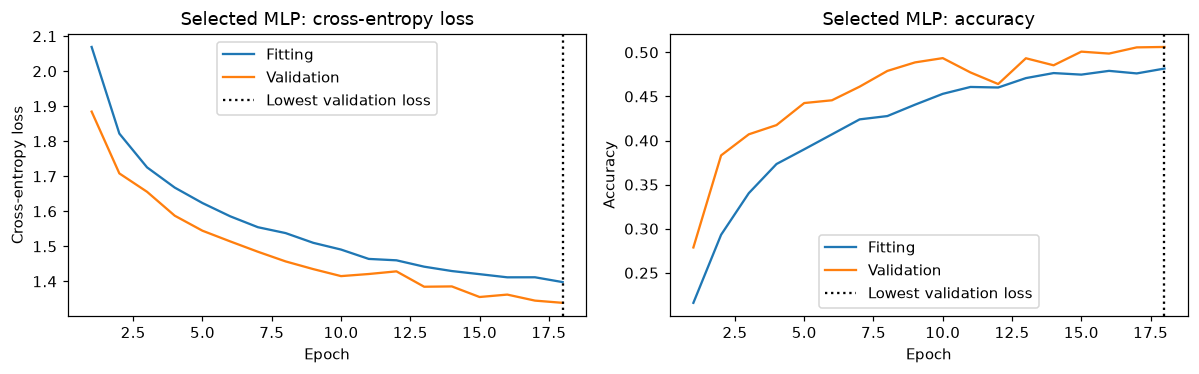

The selected combination is **width 128, dropout 0.2, learning rate 0.001**. It achieved validation macro-F1 **0.4649**, accuracy **0.5061**, and balanced accuracy **0.4915**. The lowest validation loss occurred at epoch 18; this fixes the final training duration before testing. The plotted curves and candidate charts show the observed effects of learning rate, capacity, dropout, convergence time and fitting/validation gap. These are holdout observations, not causal ablations or evidence of a global optimum.

In [15]:
mlp_plot = mlp_search_results.sort_values('candidate')
labels = [f"W={int(r.hidden_units)}, D={r.dropout_rate:g}, LR={r.learning_rate:g}"
          for r in mlp_plot.itertuples()]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ypos = np.arange(len(mlp_plot))
axes[0].barh(ypos, mlp_plot['validation_macro_f1'], color='#4C78A8')
axes[0].set(xlabel='Validation macro-F1', ylabel='Candidate',
            title='MLP validation performance', yticks=ypos, yticklabels=labels)
axes[1].barh(ypos, mlp_plot['fit_seconds'], color='#F58518')
axes[1].set(xlabel='Training time (seconds)', ylabel='Candidate',
            title='MLP candidate training time', yticks=ypos, yticklabels=labels)
fig.tight_layout(); plt.show()

best_curves = mlp_search_histories[int(mlp_selected['candidate'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
epochs = np.arange(1, len(best_curves['loss']) + 1)
for ax, train_key, val_key, label in zip(
        axes, ['loss', 'accuracy'], ['val_loss', 'val_accuracy'],
        ['Cross-entropy loss', 'Accuracy']):
    ax.plot(epochs, best_curves[train_key], label='Fitting')
    ax.plot(epochs, best_curves[val_key], label='Validation')
    ax.axvline(selected_mlp_epochs, color='black', linestyle=':',
               label='Lowest validation loss')
    ax.set(xlabel='Epoch', ylabel=label, title=f'Selected MLP: {label.lower()}')
    ax.legend()
fig.tight_layout(); plt.show()

display(Markdown(
    f"The selected combination is **width {selected_mlp_params['hidden_units']}, "
    f"dropout {selected_mlp_params['dropout_rate']}, learning rate "
    f"{selected_mlp_params['learning_rate']}**. It achieved validation macro-F1 "
    f"**{mlp_selected['validation_macro_f1']:.4f}**, accuracy "
    f"**{mlp_selected['validation_accuracy']:.4f}**, and balanced accuracy "
    f"**{mlp_selected['validation_balanced_accuracy']:.4f}**. "
    f"The lowest validation loss occurred at epoch {selected_mlp_epochs}; "
    f"this fixes the final training duration before testing. The plotted curves and "
    f"candidate charts show the observed effects of learning rate, capacity, "
    f"dropout, convergence time and fitting/validation gap. These are holdout "
    f"observations, not causal ablations or evidence of a global optimum."))

Each MLP candidate restores the weights at its lowest observed validation loss. The grid then ranks these restored models by macro-F1. The winning best-loss epoch is frozen as the full-training duration. If a winner reaches the eighteen-epoch cap, the bounded experiment cannot establish that training has converged.

### 3.3 CNN — hyperparameter search and validation results


Search all eight combinations of base filters {16, 32}, dropout {0.3, 0.5} and Adam learning rate {0.001, 0.0003}. Convolutions, pooling and the output layer are fixed; batch size is 128 and every candidate trains for twenty epochs. Increasing filters tests capacity; dropout tests regularisation; learning rate tests optimisation speed within the fixed budget. Select by last-epoch validation macro-F1, with accuracy and smaller parameter values as tie-breaks. A single holdout keeps runtime feasible; no cross-validation uncertainty or global optimum is claimed.

In [16]:
CNN_SEARCH_GRID = {'base_filters': [16, 32], 'dropout_rate': [0.3, 0.5],
                   'learning_rate': [0.001, 0.0003]}
cnn_records, cnn_search_histories = [], {}
started = perf_counter()
for trial, params in enumerate(ParameterGrid(CNN_SEARCH_GRID), start=1):
    record, curves = fit_and_score_cnn(params)
    record['candidate'] = trial
    cnn_records.append(record); cnn_search_histories[trial] = curves
    print(f"{trial}/8: {params}; macro-F1={record['validation_macro_f1']:.4f}; "
          f"accuracy={record['validation_accuracy']:.4f}; fit={record['fit_seconds']:.1f}s", flush=True)
cnn_search_wall_seconds = perf_counter() - started
cnn_search_results = pd.DataFrame(cnn_records).sort_values(
    ['validation_macro_f1', 'validation_accuracy', 'base_filters', 'dropout_rate', 'learning_rate'],
    ascending=[False, False, True, True, True]).reset_index(drop=True)
cnn_selected = cnn_search_results.iloc[0]
selected_cnn_params = {'base_filters': int(cnn_selected['base_filters']),
                       'dropout_rate': float(cnn_selected['dropout_rate']),
                       'learning_rate': float(cnn_selected['learning_rate'])}
display(cnn_search_results.round(4))
print('Validation-selected CNN parameters:', selected_cnn_params)
print(f'CNN search wall time: {cnn_search_wall_seconds:.1f}s')

1/8: {'base_filters': 16, 'dropout_rate': 0.3, 'learning_rate': 0.001}; macro-F1=0.7430; accuracy=0.7534; fit=80.8s
2/8: {'base_filters': 16, 'dropout_rate': 0.3, 'learning_rate': 0.0003}; macro-F1=0.6975; accuracy=0.7073; fit=80.0s
3/8: {'base_filters': 16, 'dropout_rate': 0.5, 'learning_rate': 0.001}; macro-F1=0.7295; accuracy=0.7305; fit=79.1s
4/8: {'base_filters': 16, 'dropout_rate': 0.5, 'learning_rate': 0.0003}; macro-F1=0.6931; accuracy=0.7028; fit=80.2s
5/8: {'base_filters': 32, 'dropout_rate': 0.3, 'learning_rate': 0.001}; macro-F1=0.7633; accuracy=0.7681; fit=151.2s
6/8: {'base_filters': 32, 'dropout_rate': 0.3, 'learning_rate': 0.0003}; macro-F1=0.7255; accuracy=0.7356; fit=157.7s
7/8: {'base_filters': 32, 'dropout_rate': 0.5, 'learning_rate': 0.001}; macro-F1=0.7744; accuracy=0.7820; fit=152.5s
8/8: {'base_filters': 32, 'dropout_rate': 0.5, 'learning_rate': 0.0003}; macro-F1=0.7254; accuracy=0.7333; fit=158.9s
Validation-selected CNN parameters: {'base_filters': 32, 'dropou

,base_filters,dropout_rate,learning_rate,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,fit_seconds,validation_predict_seconds,epochs_run,validation_loss,parameters,candidate
0,32,0.5,0.0010,0.7820,0.7744,0.7746,152.5273,0.6382,20,0.6243,33801,7
1,32,0.3,0.0010,0.7681,0.7633,0.7613,151.1856,0.6154,20,0.6568,33801,5
2,16,0.3,0.0010,0.7534,0.7430,0.7391,80.8436,0.4081,20,0.7051,12297,1
3,16,0.5,0.0010,0.7305,0.7295,0.7248,79.0604,0.4035,20,0.7651,12297,3
4,32,0.3,0.0003,0.7356,0.7255,0.7263,157.7398,0.6477,20,0.7494,33801,6
5,32,0.5,0.0003,0.7333,0.7254,0.7261,158.9179,0.6449,20,0.7602,33801,8
6,16,0.3,0.0003,0.7073,0.6975,0.6985,79.9905,0.3881,20,0.8376,12297,2
7,16,0.5,0.0003,0.7028,0.6931,0.6973,80.2025,0.3859,20,0.8330,12297,4


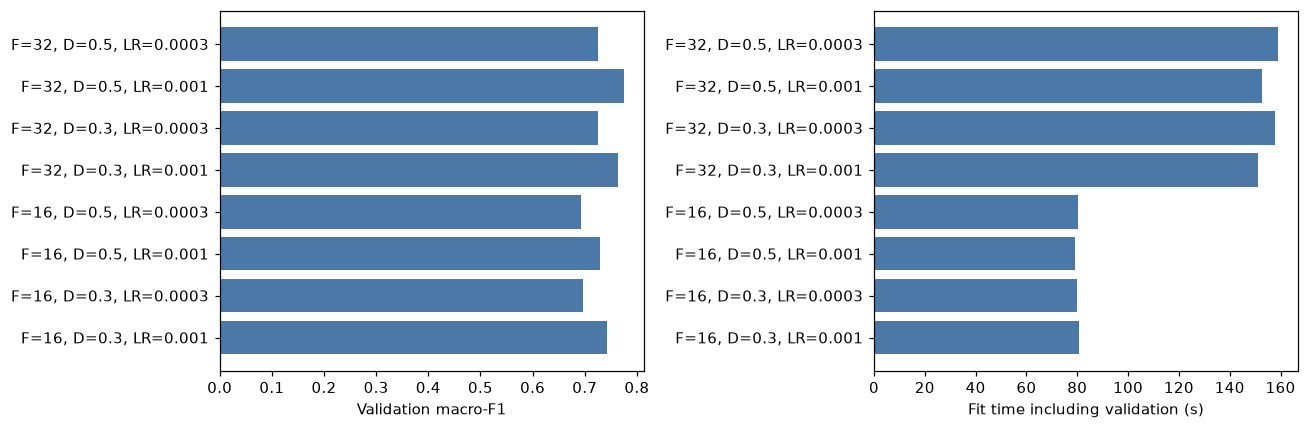

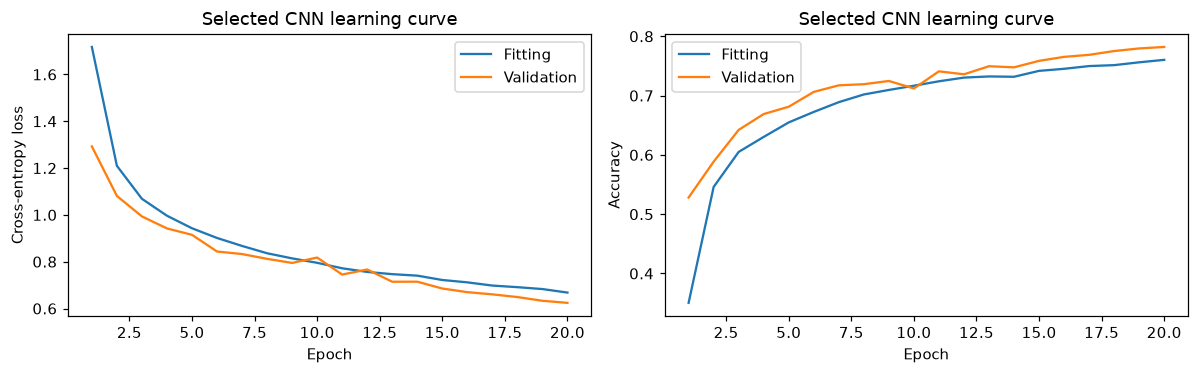

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rows = cnn_search_results.sort_values('candidate')
labels = [f"F={int(r.base_filters)}, D={r.dropout_rate:g}, LR={r.learning_rate:g}"
          for r in rows.itertuples()]
for ax, column, label in zip(axes, ['validation_macro_f1', 'fit_seconds'],
                             ['Validation macro-F1', 'Fit time including validation (s)']):
    ax.barh(np.arange(len(rows)), rows[column], color='#4C78A8')
    ax.set(yticks=np.arange(len(rows)), yticklabels=labels, xlabel=label)
fig.tight_layout(); plt.show()
curves = cnn_search_histories[int(cnn_selected['candidate'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, key, label in zip(axes, ['loss', 'accuracy'], ['Cross-entropy loss', 'Accuracy']):
    epochs = np.arange(1, len(curves[key]) + 1)
    ax.plot(epochs, curves[key], label='Fitting')
    ax.plot(epochs, curves['val_' + key], label='Validation')
    ax.set(xlabel='Epoch', ylabel=label, title='Selected CNN learning curve'); ax.legend()
fig.tight_layout(); plt.show()

The candidate table and learning curves report the observed trade-offs. Twenty epochs is a fixed comparison budget rather than a convergence guarantee. Baseline and grid candidates have different schedules (ten versus twenty epochs), so their score difference is not a controlled hyperparameter-only ablation.

## 4. Final models

Train and evaluate the selected **SVM**, then **MLP**, then **CNN**. After all three final evaluations, Section 4.4 combines their results in one comparison table.


### 4.1 SVM — final training and test evaluation


The literal parameters below are frozen from Section 3 before final test evaluation. A new scaling/PCA/SVM pipeline is fitted on all 32,000 training images. This cell does not depend on any search variables or fitted tuning models. Fit and prediction timers include the respective deterministic pixel preprocessing and PCA work.

Full-training PCA retained variance: 0.8158858


,model,training_images,test_accuracy,test_macro_f1,test_balanced_accuracy,fit_seconds,test_predict_seconds,support_vectors
0,PCA + RBF SVM,32000,0.6279,0.6221,0.6239,28.9401,16.4966,25775


,precision,recall,f1-score,support
adipose,0.8415,0.9485,0.8918,873.0
background,0.9509,0.9021,0.9258,858.0
debris,0.4178,0.4059,0.4118,877.0
lymphocytes,0.8611,0.8545,0.8578,914.0
mucus,0.5280,0.5251,0.5265,737.0
smooth muscle,0.6469,0.4991,0.5635,1072.0
normal colon mucosa,0.3817,0.3739,0.3778,682.0
cancer-associated stroma,0.4591,0.5314,0.4926,813.0
colorectal adenocarcinoma epithelium,0.5298,0.5750,0.5515,1174.0


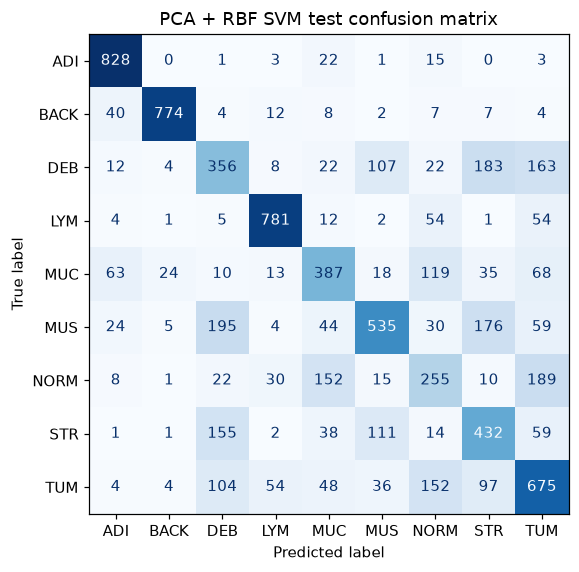

In [18]:
BEST_SVM_PARAMS = {'C': 10.0, 'gamma': 0.01}
final_svm = Pipeline([
    ('pixels', FunctionTransformer(flatten_and_scale, validate=False)),
    ('pca', PCA(n_components=64, whiten=True, svd_solver='randomized', random_state=SEED)),
    ('svm', SVC(kernel='rbf', cache_size=512, **BEST_SVM_PARAMS))])
started = perf_counter(); final_svm.fit(X_train, y_train)
svm_fit_seconds = perf_counter() - started
started = perf_counter(); y_test_pred_svm = final_svm.predict(X_test)
svm_predict_seconds = perf_counter() - started
svm_metrics = classification_scores(y_test, y_test_pred_svm)
svm_final_row = {'model': 'PCA + RBF SVM', 'training_images': len(y_train),
                 **{'test_' + k: v for k, v in svm_metrics.items()},
                 'fit_seconds': svm_fit_seconds, 'test_predict_seconds': svm_predict_seconds,
                 'support_vectors': int(final_svm.named_steps['svm'].n_support_.sum())}
svm_test_report = show_final_results('PCA + RBF SVM', y_test_pred_svm, svm_final_row)
print('Full-training PCA retained variance:', final_svm.named_steps['pca'].explained_variance_ratio_.sum())

Interpret class-level precision, recall and F1 alongside aggregate scores. The reported support-vector count helps explain SVM prediction cost; it is not directly comparable to the number of neural-network trainable parameters.

### 4.2 MLP — final training and test evaluation


Recreate the selected MLP directly from literal parameters and its validation-selected epoch count. Train on all 32,000 images without early stopping or a held-out validation fraction. Scaling is included inside the timing boundaries for consistency with the SVM pipeline. No MLP baseline/search cell is required.

,model,training_images,epochs,test_accuracy,test_macro_f1,test_balanced_accuracy,fit_seconds,test_predict_seconds,parameters
0,MLP,32000,18,0.5142,0.4776,0.4979,9.9274,0.173,310025


,precision,recall,f1-score,support
adipose,0.7674,0.9370,0.8437,873.0
background,0.7783,0.7121,0.7438,858.0
debris,0.4082,0.2281,0.2926,877.0
lymphocytes,0.5188,0.6794,0.5883,914.0
mucus,0.5560,0.5794,0.5674,737.0
smooth muscle,0.4399,0.4095,0.4242,1072.0
normal colon mucosa,0.2943,0.1217,0.1722,682.0
cancer-associated stroma,0.2831,0.1132,0.1617,813.0
colorectal adenocarcinoma epithelium,0.3940,0.7010,0.5044,1174.0


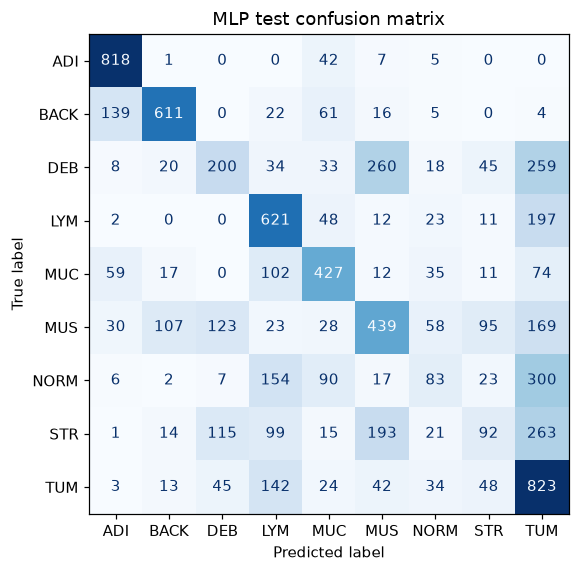

In [19]:
BEST_MLP_PARAMS = {'hidden_units': 128, 'dropout_rate': 0.2, 'learning_rate': 0.001}
FINAL_MLP_EPOCHS = 18
# Fresh initialisation; no state from a tuning model is reused.
tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
final_mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 3)), tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(BEST_MLP_PARAMS['hidden_units'], activation='relu'),
    tf.keras.layers.Dense(BEST_MLP_PARAMS['hidden_units'] // 2, activation='relu'),
    tf.keras.layers.Dropout(BEST_MLP_PARAMS['dropout_rate']),
    tf.keras.layers.Dense(len(CLASS_IDS), activation='softmax')], name='final_mlp')
final_mlp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=BEST_MLP_PARAMS['learning_rate']),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
started = perf_counter()
X_train_mlp = scale_images(X_train)
final_mlp_history = final_mlp.fit(X_train_mlp, y_train, epochs=FINAL_MLP_EPOCHS,
                                 batch_size=256, shuffle=True, verbose=0)
mlp_fit_seconds = perf_counter() - started
started = perf_counter()
X_test_mlp = scale_images(X_test)
y_test_pred_mlp = final_mlp.predict(X_test_mlp, batch_size=256, verbose=0).argmax(axis=1)
mlp_predict_seconds = perf_counter() - started
mlp_metrics = classification_scores(y_test, y_test_pred_mlp)
mlp_final_row = {'model': 'MLP', 'training_images': len(y_train), 'epochs': FINAL_MLP_EPOCHS,
                 **{'test_' + k: v for k, v in mlp_metrics.items()},
                 'fit_seconds': mlp_fit_seconds, 'test_predict_seconds': mlp_predict_seconds,
                 'parameters': final_mlp.count_params()}
mlp_test_report = show_final_results('MLP', y_test_pred_mlp, mlp_final_row)
del X_train_mlp, X_test_mlp; _ = gc.collect()

The epoch budget was fixed from validation before test scoring. Final models train without a validation split; their training losses alone cannot diagnose generalisation. The tuning learning curves, rather than repeated test inspection, guide the limitations discussed in the report.

### 4.3 CNN — final training and test evaluation


Recreate the selected two-convolution CNN directly, then train all 32,000 images for the predetermined twenty epochs. There is no early stopping or validation fraction in this final fit. Pixel scaling is included in fit/prediction timing. Neither the CNN builder in Section 2 nor the Section 3 search is required.

In [20]:
BEST_CNN_PARAMS = {'base_filters': 32, 'dropout_rate': 0.5, 'learning_rate': 0.001}
FINAL_CNN_EPOCHS = 20
tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
final_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 3)),
    tf.keras.layers.Conv2D(BEST_CNN_PARAMS['base_filters'], (3, 3), activation='relu', padding='valid'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(BEST_CNN_PARAMS['base_filters'] * 2, (3, 3), activation='relu', padding='valid'),
    tf.keras.layers.MaxPooling2D((2, 2)), tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(BEST_CNN_PARAMS['dropout_rate']),
    tf.keras.layers.Dense(len(CLASS_IDS), activation='softmax')], name='final_cnn')
final_cnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=BEST_CNN_PARAMS['learning_rate']),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
started = perf_counter()
X_train_full_cnn = scale_images(X_train)
final_cnn_history = final_cnn.fit(X_train_full_cnn, y_train, epochs=FINAL_CNN_EPOCHS,
                                 batch_size=128, shuffle=True, verbose=0)
cnn_fit_seconds = perf_counter() - started
print(f'Final CNN: {len(y_train):,} training images; {FINAL_CNN_EPOCHS} epochs; {final_cnn.count_params():,} parameters')

Final CNN: 32,000 training images; 20 epochs; 33,801 parameters


,model,training_images,epochs,test_accuracy,test_macro_f1,test_balanced_accuracy,fit_seconds,test_predict_seconds,parameters
0,CNN,32000,20,0.7945,0.783,0.7855,172.7226,0.8441,33801


,precision,recall,f1-score,support
adipose,0.8993,0.9714,0.9339,873.0
background,0.9552,0.9452,0.9502,858.0
debris,0.7044,0.6602,0.6816,877.0
lymphocytes,0.9487,0.9508,0.9497,914.0
mucus,0.6777,0.8589,0.7576,737.0
smooth muscle,0.8000,0.6978,0.7454,1072.0
normal colon mucosa,0.7640,0.5982,0.6711,682.0
cancer-associated stroma,0.6620,0.4674,0.5479,813.0
colorectal adenocarcinoma epithelium,0.7234,0.9199,0.8099,1174.0


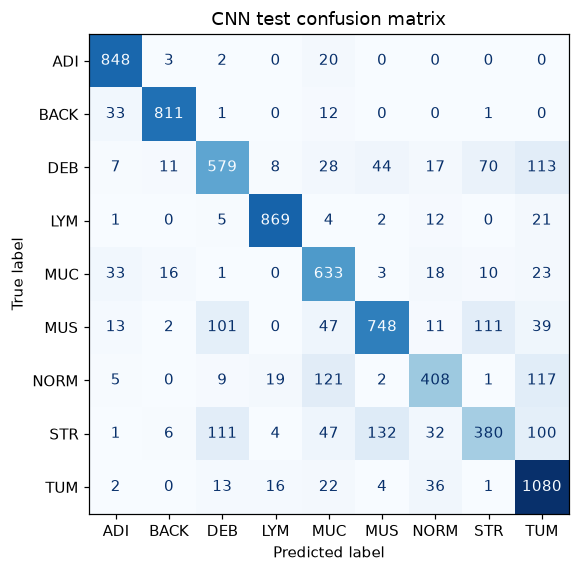

In [21]:
started = perf_counter()
X_test_cnn = scale_images(X_test)
y_test_pred_cnn = final_cnn.predict(X_test_cnn, batch_size=128, verbose=0).argmax(axis=1)
cnn_predict_seconds = perf_counter() - started
cnn_metrics = classification_scores(y_test, y_test_pred_cnn)
cnn_final_row = {'model': 'CNN', 'training_images': len(y_train), 'epochs': FINAL_CNN_EPOCHS,
                 **{'test_' + k: v for k, v in cnn_metrics.items()},
                 'fit_seconds': cnn_fit_seconds, 'test_predict_seconds': cnn_predict_seconds,
                 'parameters': final_cnn.count_params()}
cnn_test_report = show_final_results('CNN', y_test_pred_cnn, cnn_final_row)
del X_train_full_cnn, X_test_cnn; _ = gc.collect()

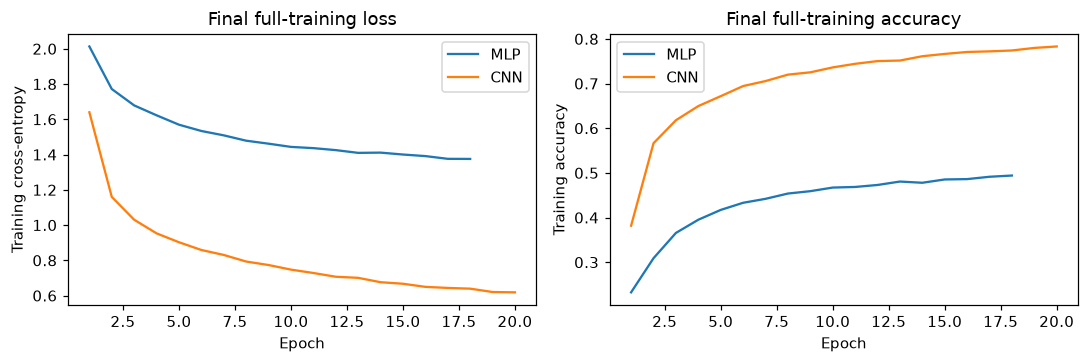

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for history, label in [(final_mlp_history, 'MLP'), (final_cnn_history, 'CNN')]:
    epochs = np.arange(1, len(history.history['loss']) + 1)
    axes[0].plot(epochs, history.history['loss'], label=label)
    axes[1].plot(epochs, history.history['accuracy'], label=label)
axes[0].set(xlabel='Epoch', ylabel='Training cross-entropy', title='Final full-training loss')
axes[1].set(xlabel='Epoch', ylabel='Training accuracy', title='Final full-training accuracy')
for ax in axes: ax.legend()
fig.tight_layout(); plt.show()

### 4.4 Final comparison
All rows below are generated from the final models executed in this notebook, using the same CPU environment and all 32,000 training images. Timers include deterministic image scaling; SVM timers additionally include learned PCA fitting/transformation. Network construction is outside fitting timers. Neural tuning fits include validation work; final fits do not. Timings are single runs with first-call/framework overhead, and do not establish hardware-independent speed rankings.

In [23]:
model_comparison = pd.DataFrame([svm_final_row, mlp_final_row, cnn_final_row])
columns = ['model', 'training_images', 'test_accuracy', 'test_macro_f1',
           'test_balanced_accuracy', 'fit_seconds', 'test_predict_seconds']
display(model_comparison[columns].round(4))
per_class_recall = pd.DataFrame({
    'class': CLASS_SHORT, 'test_support': np.bincount(y_test, minlength=9),
    'SVM': svm_test_report.loc[CLASS_NAMES, 'recall'].to_numpy(),
    'MLP': mlp_test_report.loc[CLASS_NAMES, 'recall'].to_numpy(),
    'CNN': cnn_test_report.loc[CLASS_NAMES, 'recall'].to_numpy()})
display(per_class_recall.round(4))

,model,training_images,test_accuracy,test_macro_f1,test_balanced_accuracy,fit_seconds,test_predict_seconds
0,PCA + RBF SVM,32000,0.6279,0.6221,0.6239,28.9401,16.4966
1,MLP,32000,0.5142,0.4776,0.4979,9.9274,0.1730
2,CNN,32000,0.7945,0.7830,0.7855,172.7226,0.8441


,class,test_support,SVM,MLP,CNN
0,ADI,873,0.9485,0.9370,0.9714
1,BACK,858,0.9021,0.7121,0.9452
2,DEB,877,0.4059,0.2281,0.6602
3,LYM,914,0.8545,0.6794,0.9508
4,MUC,737,0.5251,0.5794,0.8589
5,MUS,1072,0.4991,0.4095,0.6978
6,NORM,682,0.3739,0.1217,0.5982
7,STR,813,0.5314,0.1132,0.4674
8,TUM,1174,0.5750,0.7010,0.9199


## 5. AI Acknowledgement


**Tool used:** OpenAI ChatGPT/Codex.

**Use:** AI assisted with interpreting the task, drafting and debugging preprocessing and model code, designing bounded validation searches, combining group contributions, checking execution dependencies, running the notebook, producing tables/plots, and editing the report. This revision reruns the complete notebook in a common CPU environment and verifies that final-model cells can run without the baseline/search cells. Report figures and numerical claims are generated from those outputs. The report reflections retain the group draft and should be verified individually by the three students.

### References
1. Yang, J. et al. (2023). MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical image classification. Scientific Data 10, 41. https://doi.org/10.1038/s41597-022-01721-8
2. MedMNIST official PathMNIST metadata: https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py . Data source is the course-provided subset (CC BY 4.0), not a newly downloaded benchmark split.
3. scikit-learn, SVM and PCA documentation: https://scikit-learn.org/stable/modules/svm.html and https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
4. Keras, Conv2D, Dropout, Adam and EarlyStopping documentation: https://keras.io/api/ .